# Viabilidad de una captura 802.11 para el modelado estocástico de un punto de acceso

Auditoría de una captura `pcap` en modo monitor. El objetivo no es ajustar un modelo de colas, sino decidir si la muestra tiene la calidad estructural, temporal y estadística necesaria para alimentar un modelo de simulación de eventos discretos. La salida es un dictamen de usabilidad con evidencia cuantitativa, no una estimación de desempeño.

Cinco frentes, cada uno con una regla de aceptación explícita: integridad del contenedor, identificación del servicio, independencia y tamaño muestral, bondad de ajuste de los arribos y observabilidad del servicio y las pérdidas.

## 1. Marco teórico aplicable

### 1.1. Hipótesis estructural

Notación extendida de Kendall $A/B/c/K/N/D$: $A$ y $B$ son las distribuciones de interarribos y servicio, $c$ los servidores, $K$ la capacidad, $N$ la población y $D$ la disciplina. Se contrastan:

$$M/M/1/K,\qquad M/M/1+\text{Reneging},\qquad G/G/1.$$

El símbolo $M$ exige arribos de Poisson (interarribos i.i.d. exponenciales); $G$ admite distribución general pero conserva la independencia.

### 1.2. Poisson–exponencial

Un proceso de conteo es de Poisson de tasa $\lambda$ si y solo si sus interarribos son i.i.d. con

$$f_A(a)=\lambda e^{-\lambda a},\qquad F_A(a)=1-e^{-\lambda a},\qquad E[A]=\frac{1}{\lambda},\quad a\ge 0.$$

El estimador de máxima verosimilitud es

$$\hat{\lambda}=\frac{n}{\sum_{i=1}^{n}A_i}=\frac{1}{\bar A}.$$

La verificación se hace sobre los intervalos medidos, no sobre conteos agregados.

### 1.3. Falta de memoria

$$P(A>s+t\mid A>s)=e^{-\lambda t}=P(A>t),\qquad \mathrm{CV}_A=\frac{\sigma_A}{\bar A}=1\ \text{si la distribución es exponencial}.$$

Un $\mathrm{CV}_A$ marcadamente distinto de la unidad contradice la hipótesis $M$.

### 1.4. Bondad de ajuste y selección

$$D_n=\sup_x\left|F_n(x)-F_0(x)\right|,\qquad \chi_0^2=\sum_{j=1}^{k}\frac{(FO_j-FE_j)^2}{FE_j},\quad FE_j=\frac{n}{k},\quad \nu=k-p-1,$$

con $FE_j\ge 5$. Como los parámetros se estiman sobre la misma muestra, el $p$-valor de KS se calcula por remuestreo paramétrico con reajuste. Para familias no anidadas:

$$\mathrm{AIC}=2p-2\ln\hat L,\qquad \mathrm{BIC}=p\ln n-2\ln\hat L.$$

Aquí $p$ cuenta solo parámetros libres: el origen fijado en cero no se cuenta.

### 1.5. Independencia y tamaño muestral

$$\hat\rho_k=\frac{\sum_{i=1}^{n-k}(A_i-\bar A)(A_{i+k}-\bar A)}{\sum_{i=1}^{n}(A_i-\bar A)^2},\qquad Q_{LB}=n(n+2)\sum_{k=1}^{h}\frac{\hat\rho_k^2}{n-k}\sim\chi_h^2,$$

$$n\ge\left(\frac{z_{1-\alpha/2}\,s}{\epsilon\,\bar A}\right)^2.$$

Bajo independencia, $|\hat\rho_k|\le z_{1-\alpha/2}/\sqrt n$ aproximadamente.

### 1.6. Indicadores de cola (si $M/M/1$ fuera admisible)

$$\rho=\frac{\lambda}{\mu},\qquad L_q=\frac{\rho^2}{1-\rho},\qquad W_q=\frac{L_q}{\lambda},\qquad L=L_q+\rho.$$

Con capacidad finita $K$:

$$P_K=\frac{(1-\rho)\rho^K}{1-\rho^{K+1}},\qquad \lambda_{\mathrm{eff}}=\lambda(1-P_K).$$

Con servicio general, Pollaczek–Khintchine:

$$L_q^{(PK)}=\frac{\lambda^2\sigma_S^2+\rho^2}{2(1-\rho)}.$$

Esto exige $\rho<1$ y $\lambda,\mu$ estimables. En una captura de radio solo se observa el tiempo de transmisión, $S_{\mathrm{proxy}}=8L_{\mathrm{MPDU}}/R_{\mathrm{PHY}}$: es una cota inferior del tiempo de atención, no una medida de uso de CPU.

## 2. Configuración

Las dependencias se instalan en el entorno Jupyter antes de la ejecución. La celda siguiente permanece comentada para no alterar el entorno durante una ejecución automatizada.

In [1]:
# python -m pip install --upgrade numpy pandas scipy matplotlib

In [2]:
from pathlib import Path
import struct

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

PCAP_PATH = Path("data/cap_pico_20261029_1842.pcap")
ALPHA = 0.05
REL_PRECISION = 0.05
N_BINS = 10
N_BOOT = 399
LAGS = 10
WINDOW_S = 60.0
PHY_RATE_BPS = 54e6
FCS_BYTES = 4
TARGET_BSSID = None
EXPORT_CLEAN = False
SEED = 20261029

plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", lambda v: f"{v:.6g}")

## 3. Ingesta y validación del contenedor

Cada registro de un archivo `pcap` clásico se estructura como

$$\underbrace{(ts_{\mathrm{sec}},\,ts_{\mathrm{frac}},\,incl_{\mathrm{len}},\,orig_{\mathrm{len}})}_{16\ \text{bytes}}\;\|\;\mathrm{payload}(incl_{\mathrm{len}}),\qquad t=ts_{\mathrm{sec}}+\frac{ts_{\mathrm{frac}}}{10^6}.$$

El campo `incl_len` son los bytes almacenados y `orig_len` los del medio; su diferencia cuantifica la pérdida de información por recorte (*snapshot length*).

In [3]:
MAGIC = {
    b"\xd4\xc3\xb2\xa1": ("<", False),
    b"\x4d\x3c\xb2\xa1": ("<", True),
    b"\xa1\xb2\xc3\xd4": (">", False),
    b"\xa1\xb2\x3c\x4d": (">", True),
}


def read_pcap(path):
    with path.open("rb") as fh:
        header = fh.read(24)
        if len(header) != 24:
            raise ValueError("Encabezado global incompleto")
        if header[:4] not in MAGIC:
            raise ValueError(f"Magic number desconocido: {header[:4].hex()}")
        endian, nanoseconds = MAGIC[header[:4]]
        version = struct.unpack(endian + "HH", header[4:8])
        _, _, snaplen, linktype = struct.unpack(endian + "IIII", header[8:24])
        records = []
        while True:
            record_header = fh.read(16)
            if len(record_header) == 0:
                break
            if len(record_header) != 16:
                raise ValueError("Registro incompleto al final del archivo")
            sec, frac, incl, orig = struct.unpack(endian + "IIII", record_header)
            payload = fh.read(incl)
            if len(payload) != incl:
                raise ValueError("Payload incompleto en un registro")
            ts = sec + frac / (1e9 if nanoseconds else 1e6)
            records.append((ts, incl, orig, payload))
    meta = {
        "version": version,
        "snaplen": snaplen,
        "linktype": linktype,
        "nanoseconds": nanoseconds,
        "size_bytes": path.stat().st_size,
    }
    return pd.DataFrame(records, columns=["ts", "incl_len", "orig_len", "payload"]), meta


frames, meta = read_pcap(PCAP_PATH)
print("Registros leídos:", len(frames))
print("Metadatos:", meta)

Registros leídos: 3425
Metadatos: {'version': (2, 4), 'snaplen': 128, 'linktype': 127, 'nanoseconds': False, 'size_bytes': 454140}


## 4. Decodificación 802.11 y selección del servicio

El encabezado `radiotap` indica en `it_len` (offset 2) dónde comienza la trama 802.11. Del campo de control se extraen tipo, subtipo y los bits de distribución:

$$FC=\text{subtype}\cdot2^4+\text{type}\cdot2^2+\mathrm{ToDS}\cdot2^8+\mathrm{FromDS}\cdot2^9+\dots$$

El BSSID depende de los bits `ToDS` y `FromDS`:

| ToDS | FromDS | BSSID |
|:---:|:---:|:---|
| 0 | 0 | `Addr3` |
| 1 | 0 | `Addr1` |
| 0 | 1 | `Addr2` |
| 1 | 1 | no definido (WDS) |

Se conservan solo tramas de datos con carga útil, es decir `subtype & 4 == 0`. Las tramas nulas y de control no transportan datos de usuario.

In [4]:
def mac_address(buffer, offset):
    return ":".join(f"{byte:02x}" for byte in buffer[offset:offset + 6])


def decode_frame(payload):
    if len(payload) < 8:
        return (np.nan, -1, -1, -1, None, None, None)
    it_len = struct.unpack_from("<H", payload, 2)[0]
    if not (8 <= it_len <= len(payload) - 2):
        return (np.nan, -1, -1, -1, None, None, None)
    fc = struct.unpack_from("<H", payload, it_len)[0]
    ftype = (fc >> 2) & 0x3
    subtype = (fc >> 4) & 0xF
    to_ds = (fc >> 8) & 1
    from_ds = (fc >> 9) & 1
    if len(payload) < it_len + 24:
        return (it_len, ftype, subtype, -1, None, None, None)
    addr1 = mac_address(payload, it_len + 4)
    addr2 = mac_address(payload, it_len + 10)
    addr3 = mac_address(payload, it_len + 16)
    if not to_ds and not from_ds:
        bssid = addr3
    elif to_ds and not from_ds:
        bssid = addr1
    elif not to_ds and from_ds:
        bssid = addr2
    else:
        bssid = None
    # Origen y destino según ToDS/FromDS (WDS queda fuera del análisis).
    sa, da = (addr2, addr3) if to_ds else (addr3, addr1)
    return (it_len, ftype, subtype, 2 * to_ds + from_ds, bssid, sa, da)


decoded = pd.DataFrame(
    frames["payload"].apply(decode_frame).tolist(),
    columns=["it_len", "ftype", "fsubtype", "ds", "bssid", "sa", "da"],
    index=frames.index,
)
frames = pd.concat([frames, decoded], axis=1)

print("Tipos 802.11 (0=gestion, 1=control, 2=datos):")
print(frames["ftype"].value_counts().sort_index().to_string())
print("\nSubtipos observados:")
print(frames["fsubtype"].value_counts().sort_index().to_string())
print("\nDistribución de BSSID (primeros 5):")
print(frames["bssid"].value_counts().head(5).to_string())

Tipos 802.11 (0=gestion, 1=control, 2=datos):
ftype
2    3425

Subtipos observados:
fsubtype
8    3425

Distribución de BSSID (primeros 5):
bssid
0c:ea:14:2d:8a:27    3425


In [5]:
valid = (
    frames["it_len"].notna()
    & (frames["ftype"] == 2)
    & ((frames["fsubtype"] & 4) == 0)
    & frames["bssid"].notna()
)
bssid_counts = frames.loc[valid, "bssid"].value_counts()
target_bssid = TARGET_BSSID if TARGET_BSSID is not None else bssid_counts.index[0]
selected = frames.loc[valid & (frames["bssid"] == target_bssid)].sort_values("ts").reset_index(drop=True)
selected["mpdu_len"] = (selected["orig_len"] - selected["it_len"] - FCS_BYTES).clip(lower=0)
selected = selected.loc[selected["mpdu_len"] > 0].reset_index(drop=True)
selected["service_proxy_s"] = 8.0 * selected["mpdu_len"] / PHY_RATE_BPS

assert not selected.empty, "Sin tramas útiles tras el filtrado"

print(f"BSSID analizado: {target_bssid}")
print(f"Tramas de datos útiles: {len(selected)} de {len(frames)} registros")
print(f"Estaciones transmisoras distintas: {selected['sa'].nunique()}")

BSSID analizado: 0c:ea:14:2d:8a:27
Tramas de datos útiles: 3425 de 3425 registros
Estaciones transmisoras distintas: 61


### Composición del servicio

El BSSID dominante se aísla bien, pero pocas estaciones concentran casi todo el tráfico: esa concentración es la que luego aparece como ráfagas en los interarribos.

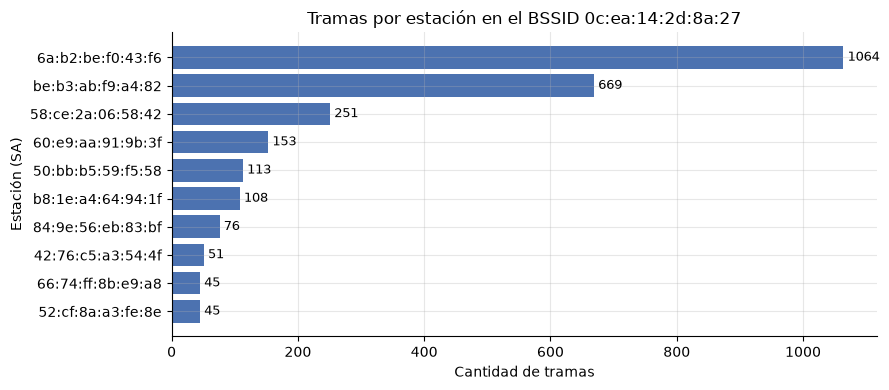

In [6]:
top_stations = selected["sa"].value_counts().head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(top_stations.index, top_stations.to_numpy(), color="#4C72B0")
ax.bar_label(bars, fmt="%d", padding=3, fontsize=9)
ax.set_title(f"Tramas por estación en el BSSID {target_bssid}")
ax.set_xlabel("Cantidad de tramas")
ax.set_ylabel("Estación (SA)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 5. Integridad temporal y resolución

Tres condiciones: monotonía de las marcas de tiempo, ausencia de marcas duplicadas y fracción de tramas recortadas,

$$\tau=\frac{1}{n}\sum_{i=1}^{n}\mathbf{1}\!\left[\,\mathrm{orig\_len}_i>\mathrm{incl\_len}_i\,\right].$$

Un valor elevado de $\tau$ invalida cualquier análisis basado en el payload, pero conserva la validez de marcas de tiempo y longitudes originales.

,control,valor,ok
0,Monotonía de marcas de tiempo,True,True
1,Marcas de tiempo duplicadas,0,True
2,Intervalos no positivos,0,True
3,Fracción de tramas recortadas,0.380438,False
4,Duración observada (s),1798.07,True


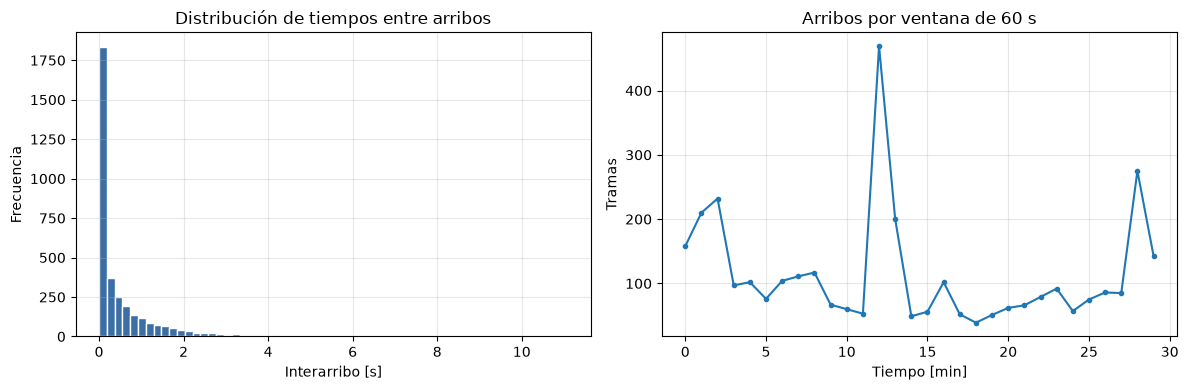

In [7]:
ts = selected["ts"].to_numpy()
deltas = np.diff(ts)
interarrivals = deltas[deltas > 0]
duration = ts[-1] - ts[0]
truncation_ratio = float((selected["orig_len"] > selected["incl_len"]).mean())
n_unique_ts = int(np.unique(ts).size)

report = pd.DataFrame(
    [
        {"control": "Monotonía de marcas de tiempo", "valor": bool(np.all(deltas >= 0)), "ok": bool(np.all(deltas >= 0))},
        {"control": "Marcas de tiempo duplicadas", "valor": len(ts) - n_unique_ts, "ok": len(ts) == n_unique_ts},
        {"control": "Intervalos no positivos", "valor": int((deltas <= 0).sum()), "ok": bool(np.all(deltas > 0))},
        {"control": "Fracción de tramas recortadas", "valor": truncation_ratio, "ok": truncation_ratio < 0.05},
        {"control": "Duración observada (s)", "valor": duration, "ok": duration > 0},
    ]
)
display(report)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(interarrivals, bins=60, color="#3b6ea5", edgecolor="white")
axes[0].set_title("Distribución de tiempos entre arribos")
axes[0].set_xlabel("Interarribo [s]")
axes[0].set_ylabel("Frecuencia")
window_ids = ((ts - ts[0]) // WINDOW_S).astype(int)
counts_per_window = np.bincount(window_ids)  # incluye ventanas vacías
axes[1].plot(np.arange(counts_per_window.size) * WINDOW_S / 60, counts_per_window, marker="o", ms=3)
axes[1].set_title(f"Arribos por ventana de {WINDOW_S:.0f} s")
axes[1].set_xlabel("Tiempo [min]")
axes[1].set_ylabel("Tramas")
plt.tight_layout()
plt.show()

### Lectura visual de la integridad

La sucesión de interarribos en escala logarítmica hace visibles las ráfagas; el segundo panel muestra que `orig_len` supera al `snaplen` en una fracción alta de tramas.

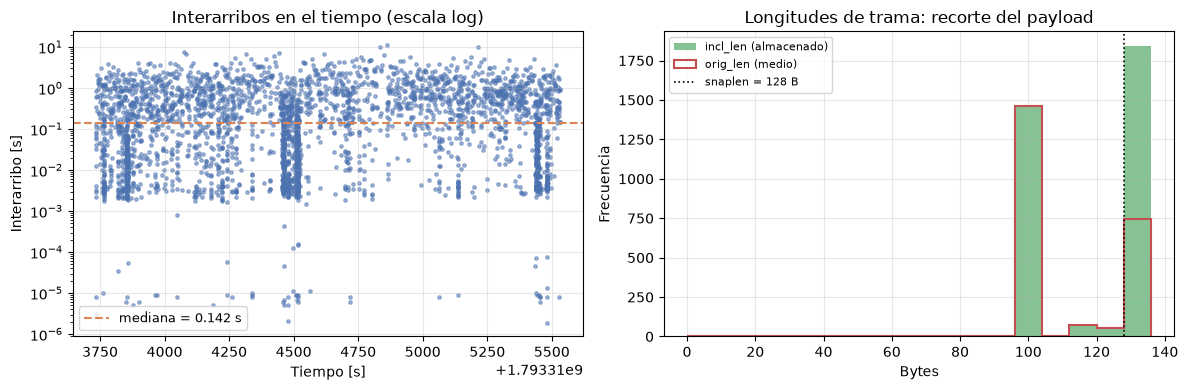

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(ts[1:], interarrivals, s=6, alpha=0.5, color="#4C72B0")
axes[0].axhline(np.median(interarrivals), color="#DD8452", ls="--", lw=1.5,
                label=f"mediana = {np.median(interarrivals):.3f} s")
axes[0].set_yscale("log")
axes[0].set_title("Interarribos en el tiempo (escala log)")
axes[0].set_xlabel("Tiempo [s]")
axes[0].set_ylabel("Interarribo [s]")
axes[0].legend(fontsize=9)

length_bins = np.arange(0, max(meta["snaplen"], selected["incl_len"].max()) + 16, 8)
axes[1].hist(selected["incl_len"], bins=length_bins, color="#55A868", alpha=0.7,
             label="incl_len (almacenado)")
axes[1].hist(selected["orig_len"], bins=length_bins, histtype="step",
             color="#C44E52", lw=1.5, label="orig_len (medio)")
axes[1].axvline(meta["snaplen"], color="black", ls=":", lw=1.2,
                label=f"snaplen = {meta['snaplen']} B")
axes[1].set_title("Longitudes de trama: recorte del payload")
axes[1].set_xlabel("Bytes")
axes[1].set_ylabel("Frecuencia")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6. Tamaño muestral e independencia

Se contrasta la independencia con el estadístico $Q_{LB}$, una prueba de rachas sobre la mediana y la banda de significación de la autocorrelación. La prueba de rachas utiliza

$$\mu_R=\frac{2n_1n_2}{n}+1,\qquad \sigma_R^2=\frac{2n_1n_2(2n_1n_2-n)}{n^2(n-1)},\qquad Z_R=\frac{R-\mu_R}{\sigma_R}.$$

n = 3424; media = 0.525138 s; desviación = 0.908182 s; CV = 1.729
λ estimada = 1.90426 arribos/s
n requerido para precisión relativa 5%: 4596
Ljung-Box Q(10) = 1260.96, p = 1.02e-264
Rachas: R = 944, esperado = 1713.0, Z = -26.29, p = 2.65e-152
ρ(1) = 0.2778; banda ±0.0335


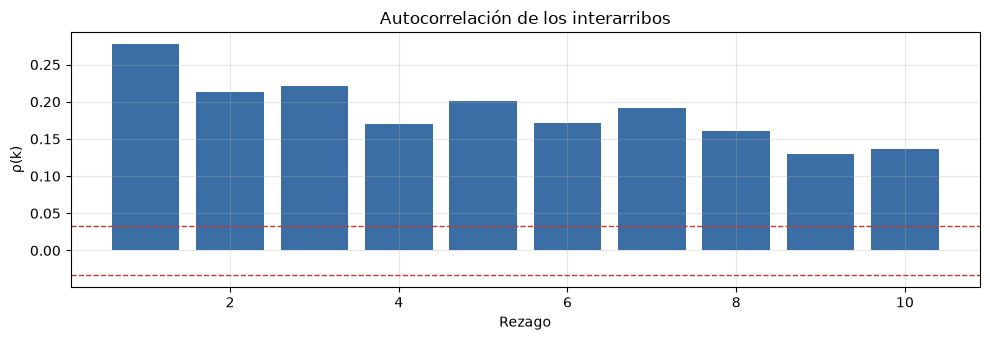

In [9]:
n = len(interarrivals)
assert n > LAGS, "Muy pocos interarribos para el análisis"
mean_ia = interarrivals.mean()
std_ia = interarrivals.std(ddof=1)
cv_ia = std_ia / mean_ia
lambda_hat = n / interarrivals.sum()
zcrit = stats.norm.ppf(1 - ALPHA / 2)
n_required = int(np.ceil((zcrit * std_ia / (REL_PRECISION * mean_ia)) ** 2))


def sample_acf(x, lags):
    xc = np.asarray(x, dtype=float) - np.mean(x)
    den = float(xc @ xc)
    return np.array([float(xc[:-k] @ xc[k:] / den) for k in lags])


lags = np.arange(1, LAGS + 1)
rho = sample_acf(interarrivals, lags)
q_lb = n * (n + 2) * np.sum(rho ** 2 / (n - lags))
p_lb = stats.chi2.sf(q_lb, len(lags))
acf_bound = zcrit / np.sqrt(n)

above = interarrivals > np.median(interarrivals)
n1, n2 = int(above.sum()), int((~above).sum())
runs = 1 + int(np.sum(above[1:] != above[:-1]))
mu_runs = 2 * n1 * n2 / n + 1
var_runs = (2 * n1 * n2 * (2 * n1 * n2 - n)) / (n ** 2 * (n - 1))
z_runs = (runs - mu_runs) / np.sqrt(var_runs)
p_runs = 2 * stats.norm.sf(abs(z_runs))

print(f"n = {n}; media = {mean_ia:.6g} s; desviación = {std_ia:.6g} s; CV = {cv_ia:.4g}")
print(f"λ estimada = {lambda_hat:.6g} arribos/s")
print(f"n requerido para precisión relativa {REL_PRECISION:.0%}: {n_required}")
print(f"Ljung-Box Q({len(lags)}) = {q_lb:.2f}, p = {p_lb:.3g}")
print(f"Rachas: R = {runs}, esperado = {mu_runs:.1f}, Z = {z_runs:.2f}, p = {p_runs:.3g}")
print(f"ρ(1) = {rho[0]:.4f}; banda ±{acf_bound:.4f}")

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(lags, rho, color="#3b6ea5")
ax.axhline(acf_bound, color="#c0392b", ls="--", lw=1)
ax.axhline(-acf_bound, color="#c0392b", ls="--", lw=1)
ax.set_title("Autocorrelación de los interarribos")
ax.set_xlabel("Rezago")
ax.set_ylabel("ρ(k)")
plt.tight_layout()
plt.show()

### Rachas sobre la mediana

La prueba cuenta cuántas veces la serie cruza la mediana. Pocos cruces implican rachas largas: bajo independencia se esperan unos dos interarribos por racha.

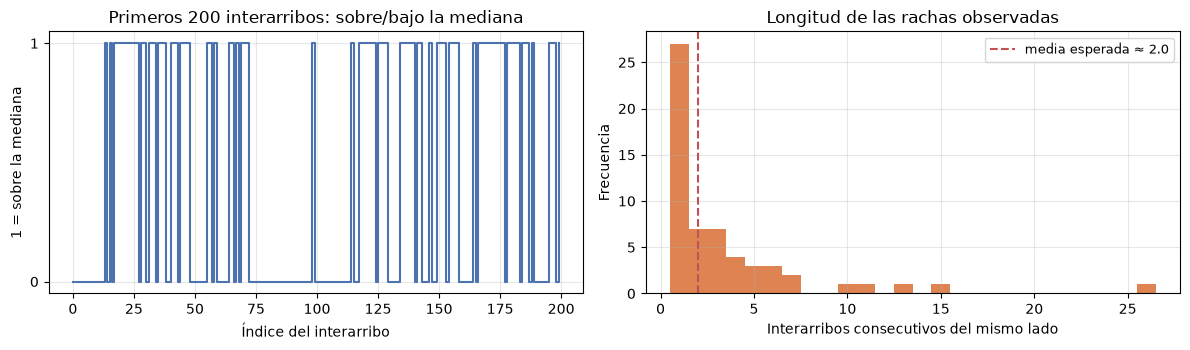

In [10]:
above_seq = (interarrivals > np.median(interarrivals)).astype(int)[:200]
run_edges = np.r_[0, np.flatnonzero(np.diff(above_seq)) + 1, above_seq.size]
run_lengths = np.diff(run_edges)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].step(np.arange(above_seq.size), above_seq, where="post", color="#4C72B0")
axes[0].set_title(f"Primeros {above_seq.size} interarribos: sobre/bajo la mediana")
axes[0].set_xlabel("Índice del interarribo")
axes[0].set_ylabel("1 = sobre la mediana")
axes[0].set_yticks([0, 1])

axes[1].hist(run_lengths, bins=np.arange(1, run_lengths.max() + 2) - 0.5, color="#DD8452")
axes[1].axvline(n / mu_runs, color="#C44E52", ls="--", lw=1.5,
                label=f"media esperada ≈ {n / mu_runs:.1f}")
axes[1].set_title("Longitud de las rachas observadas")
axes[1].set_xlabel("Interarribos consecutivos del mismo lado")
axes[1].set_ylabel("Frecuencia")
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

## 7. Ajuste del proceso de arribos

Se ajustan cinco familias por máxima verosimilitud con origen fijo en cero. Para cada una se registran $\mathrm{AIC}$, $\mathrm{BIC}$, el estadístico $D_n$, un $p$-valor por remuestreo con reajuste y la prueba de chi-cuadrado con $FE_j=n/k$. El número de parámetros libres excluye el `loc` fijado en cero.

In [11]:
families = [
    ("Exponencial", stats.expon, {"floc": 0}),
    ("Gamma", stats.gamma, {"floc": 0}),
    ("Lognormal", stats.lognorm, {"floc": 0}),
    ("Weibull", stats.weibull_min, {"floc": 0}),
    ("Uniforme", stats.uniform, {"floc": 0}),
]


def lilliefors_pvalue(x, dist, fit_kwargs, n_boot=N_BOOT, random_state=SEED):
    rng = np.random.default_rng(random_state)
    params = dist.fit(x, **fit_kwargs)
    observed = stats.kstest(x, dist.cdf, args=params).statistic
    extreme = 0
    for _ in range(n_boot):
        simulated = dist.rvs(*params, size=len(x), random_state=rng)
        refit = dist.fit(simulated, **fit_kwargs)
        statistic = stats.kstest(simulated, dist.cdf, args=refit).statistic
        extreme += statistic >= observed
    return (extreme + 1) / (n_boot + 1)


def chi_square_test(x, dist, params, p_free, n_bins=N_BINS):
    probs = np.linspace(0.0, 1.0, n_bins + 1)[1:-1]
    edges = np.concatenate(([0.0], dist.ppf(probs, *params), [np.inf]))
    observed = np.histogram(x, bins=edges)[0]
    expected = len(x) / len(observed)
    statistic = float(np.sum((observed - expected) ** 2 / expected))
    dof = len(observed) - p_free - 1
    return statistic, dof, stats.chi2.sf(statistic, dof), expected


fitted_params = {}
fit_rows = []
for name, dist, kwargs in families:
    params = dist.fit(interarrivals, **kwargs)
    fitted_params[name] = params
    loglik = float(np.sum(dist.logpdf(interarrivals, *params)))
    k = len(params) - 1  # `floc=0` no es un parámetro libre
    ks = stats.kstest(interarrivals, dist.cdf, args=params)
    p_boot = lilliefors_pvalue(interarrivals, dist, kwargs)
    chi2_stat, dof, p_chi, min_expected = chi_square_test(interarrivals, dist, params, k)
    fit_rows.append(
        {
            "familia": name,
            "parámetros": tuple(np.round(params, 4)),
            "AIC": 2 * k - 2 * loglik,
            "BIC": k * np.log(n) - 2 * loglik,
            "D_n": ks.statistic,
            "p_KS_boot": p_boot,
            "chi2": chi2_stat,
            "gl": dof,
            "p_chi2": p_chi,
            "FE_min": min_expected,
        }
    )

fits = pd.DataFrame(fit_rows).sort_values("AIC")
display(fits)
best = fits.iloc[0]
print(f"Mejor familia por AIC: {best['familia']} (AIC = {best['AIC']:.1f})")
print(f"Exponencial rechazada al {ALPHA:.0%}: {bool(fits.loc[fits['familia'] == 'Exponencial', 'p_KS_boot'].iloc[0] <= ALPHA)}")

,familia,parámetros,AIC,BIC,D_n,p_KS_boot,chi2,gl,p_chi2,FE_min
3,Weibull,"(0.5141, 0.0, 0.288)",-869.904,-857.626,0.0620529,0.0025,244.178,7,4.80328e-49,342.4
1,Gamma,"(0.3833, 0.0, 1.3701)",-810.033,-797.756,0.0724581,0.0025,678.78,7,2.58874e-142,342.4
2,Lognormal,"(2.4393, 0.0, 0.0932)",-421.965,-409.688,0.0789805,0.0025,439.616,7,7.53616e-91,342.4
0,Exponencial,"(0.0, 0.5251)",2439.24,2445.38,0.28808,0.0025,3312.88,8,0,342.4
4,Uniforme,"(0.0, 11.0764)",16470.2,16476.3,0.763513,0.0025,21598.9,8,0,342.4


Mejor familia por AIC: Weibull (AIC = -869.9)
Exponencial rechazada al 5%: True


### Comparación visual de las familias

La exponencial tiene exceso de intervalos cortos y cola más pesada de lo que la muestra necesita; Weibull se acerca en forma, pero el remuestreo la rechaza por la dependencia.

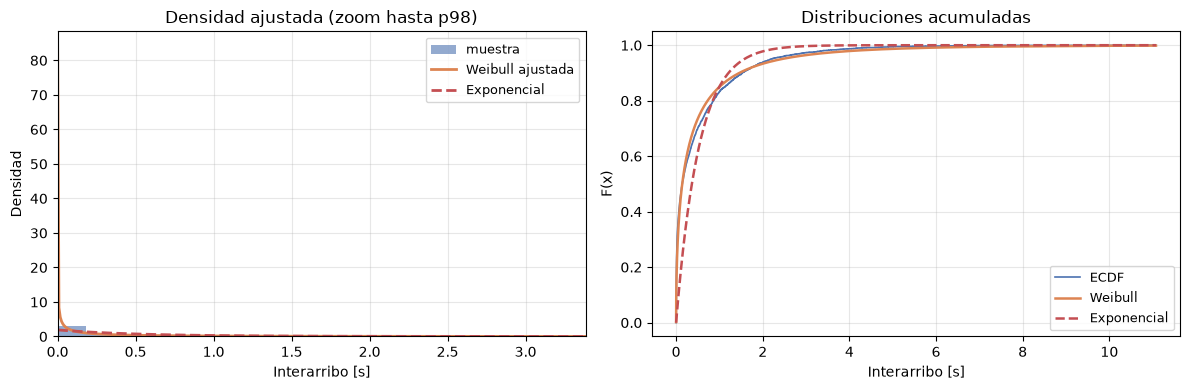

In [12]:
weibull_params = fitted_params["Weibull"]
exp_params = fitted_params["Exponencial"]
x_max = np.quantile(interarrivals, 0.98)
x_grid = np.linspace(1e-4, x_max, 400)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(interarrivals, bins=60, density=True, color="#4C72B0", alpha=0.6, label="muestra")
axes[0].plot(x_grid, stats.weibull_min.pdf(x_grid, *weibull_params),
             color="#DD8452", lw=2, label="Weibull ajustada")
axes[0].plot(x_grid, stats.expon.pdf(x_grid, *exp_params),
             color="#C44E52", ls="--", lw=2, label="Exponencial")
axes[0].set_xlim(0, x_max)
axes[0].set_title("Densidad ajustada (zoom hasta p98)")
axes[0].set_xlabel("Interarribo [s]")
axes[0].set_ylabel("Densidad")
axes[0].legend(fontsize=9)

x_ecdf = np.sort(interarrivals)
y_ecdf = np.arange(1, n + 1) / n
axes[1].step(x_ecdf, y_ecdf, where="post", color="#4C72B0", lw=1.2, label="ECDF")
axes[1].plot(x_ecdf, stats.weibull_min.cdf(x_ecdf, *weibull_params),
             color="#DD8452", lw=1.8, label="Weibull")
axes[1].plot(x_ecdf, stats.expon.cdf(x_ecdf, *exp_params),
             color="#C44E52", ls="--", lw=1.8, label="Exponencial")
axes[1].set_title("Distribuciones acumuladas")
axes[1].set_xlabel("Interarribo [s]")
axes[1].set_ylabel("F(x)")
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

## 8. Estacionariedad del régimen de arribos

Para ventanas de duración $\Delta$, el índice de dispersión

$$I=\frac{\mathrm{Var}(N_k)}{E[N_k]}$$

vale uno para un proceso de Poisson homogéneo; $I>1$ indica agrupamiento (*bursts*) y $I<1$ regularidad. Se complementa con una regresión lineal del conteo contra el tiempo, contrastando $H_0:\beta_1=0$. Las ventanas sin arribos se contabilizan como cero.

In [13]:
window_ids = ((ts - ts[0]) // WINDOW_S).astype(int)
window_counts = pd.Series(np.bincount(window_ids))  # ventanas sin arribos = 0
dispersion = window_counts.var(ddof=1) / window_counts.mean()
trend = stats.linregress(window_counts.index.to_numpy(), window_counts.to_numpy())

print(f"Ventanas analizadas: {len(window_counts)}")
print(f"Media de arribos por ventana: {window_counts.mean():.2f}")
print(f"Índice de dispersión: {dispersion:.3f} (referencia Poisson: 1)")
print(f"Pendencia: {trend.slope:.4f} arribos/ventana, p = {trend.pvalue:.4g}")

Ventanas analizadas: 30
Media de arribos por ventana: 114.17
Índice de dispersión: 69.584 (referencia Poisson: 1)
Pendencia: -1.6661 arribos/ventana, p = 0.3849


### Conteo por ventana y persistencia

El índice de dispersión $I \gg 1$ se aprecia directamente: el conteo por minuto oscila mucho alrededor de la media, sin una pendiente significativa.

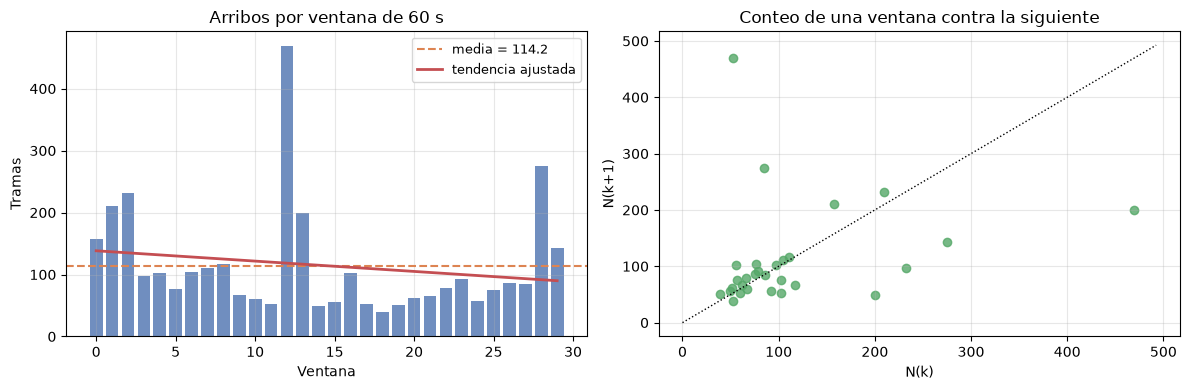

In [14]:
x_w = window_counts.index.to_numpy()
y_w = window_counts.to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(x_w, y_w, color="#4C72B0", alpha=0.8)
axes[0].axhline(window_counts.mean(), color="#DD8452", ls="--", lw=1.5,
                label=f"media = {window_counts.mean():.1f}")
axes[0].plot(x_w, trend.intercept + trend.slope * x_w, color="#C44E52", lw=2,
             label="tendencia ajustada")
axes[0].set_title(f"Arribos por ventana de {WINDOW_S:.0f} s")
axes[0].set_xlabel("Ventana")
axes[0].set_ylabel("Tramas")
axes[0].legend(fontsize=9)

axes[1].scatter(y_w[:-1], y_w[1:], color="#55A868", alpha=0.8)
limit = y_w.max() * 1.05
axes[1].plot([0, limit], [0, limit], color="black", ls=":", lw=1)
axes[1].set_title("Conteo de una ventana contra la siguiente")
axes[1].set_xlabel("N(k)")
axes[1].set_ylabel("N(k+1)")
plt.tight_layout()
plt.show()

## 9. Tiempo de servicio observable y su impacto en la cola

El tiempo de transmisión de una trama es $S_{\mathrm{proxy}}=8L_{\mathrm{MPDU}}/R_{\mathrm{PHY}}$. Su coeficiente de variación al cuadrado $H=\mathrm{CV}_S^2$ modula la diferencia entre $M/M/1$ y $M/G/1$:

$$\frac{L_q^{(PK)}}{L_q^{(M/M/1)}}=\frac{\lambda^2\sigma_S^2+\rho^2}{2\rho^2}=\frac{1+H}{2}.$$

Con $H=1$ se recupera el caso markoviano; $H>1$ indica que la variabilidad del servicio acrecienta la cola. El proxy mide transmisión en el aire, no procesamiento en el procesador.

In [15]:
mpdu = selected["mpdu_len"].to_numpy()
service = selected["service_proxy_s"].to_numpy()
rho_proxy = lambda_hat * service.mean()
cv2_service = (service.std(ddof=1) / service.mean()) ** 2
lq_mm1 = rho_proxy ** 2 / (1 - rho_proxy) if rho_proxy < 1 else np.inf
lq_pk = (lambda_hat ** 2 * service.var(ddof=1) + rho_proxy ** 2) / (2 * (1 - rho_proxy)) if rho_proxy < 1 else np.inf

print(f"Longitud MPDU: media = {mpdu.mean():.1f} B, mediana = {np.median(mpdu):.1f} B, CV = {mpdu.std(ddof=1)/mpdu.mean():.3f}")
print(f"Tiempo de servicio proxy: media = {service.mean():.3e} s, CV² = {cv2_service:.3f}")
print(f"μ proxy = {1/service.mean():.4g} tramas/s; ρ proxy = {rho_proxy:.4g}")
print(f"L_q M/M/1 = {lq_mm1:.4g}; L_q Pollaczek-Khintchine = {lq_pk:.4g}")
print("Advertencia: el proxy de servicio mide transmisión en el aire, no procesamiento en el procesador.")

Longitud MPDU: media = 118.1 B, mediana = 86.0 B, CV = 1.314
Tiempo de servicio proxy: media = 1.750e-05 s, CV² = 1.728
μ proxy = 5.716e+04 tramas/s; ρ proxy = 3.332e-05
L_q M/M/1 = 1.11e-09; L_q Pollaczek-Khintchine = 1.514e-09
Advertencia: el proxy de servicio mide transmisión en el aire, no procesamiento en el procesador.


### Origen de la variabilidad del servicio

El proxy es proporcional a la longitud MPDU, así que $CV_S^2 = CV_L^2$: la gráfica no aporta información nueva sobre el procesador.

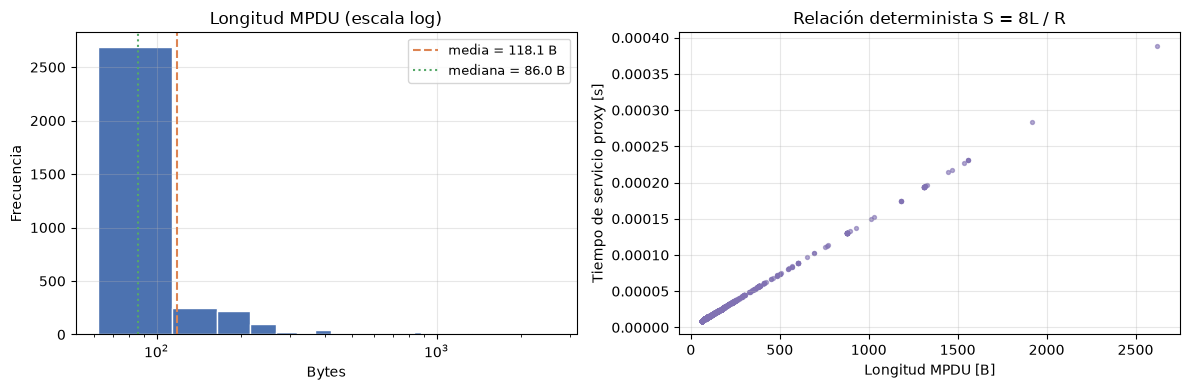

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(mpdu, bins=50, color="#4C72B0", edgecolor="white")
axes[0].axvline(mpdu.mean(), color="#DD8452", ls="--", lw=1.5,
                label=f"media = {mpdu.mean():.1f} B")
axes[0].axvline(np.median(mpdu), color="#55A868", ls=":", lw=1.5,
                label=f"mediana = {np.median(mpdu):.1f} B")
axes[0].set_xscale("log")
axes[0].set_title("Longitud MPDU (escala log)")
axes[0].set_xlabel("Bytes")
axes[0].set_ylabel("Frecuencia")
axes[0].legend(fontsize=9)

axes[1].scatter(mpdu, service, s=8, alpha=0.6, color="#8172B3")
axes[1].set_title("Relación determinista S = 8L / R")
axes[1].set_xlabel("Longitud MPDU [B]")
axes[1].set_ylabel("Tiempo de servicio proxy [s]")
plt.tight_layout()
plt.show()

## 10. Factibilidad de los indicadores de cola

Se evalúa la existencia de régimen estacionario y la sensibilidad de la probabilidad de bloqueo respecto de la capacidad $K$ del búfer.

In [17]:
def blocking_probability(rho, capacity):
    if np.isclose(rho, 1.0):
        return 1.0 / (capacity + 1)
    return ((1.0 - rho) * rho ** capacity) / (1.0 - rho ** (capacity + 1))


capacity_table = pd.DataFrame(
    [{"K": k, "P_K": blocking_probability(rho_proxy, k), "λ_eff": lambda_hat * (1 - blocking_probability(rho_proxy, k))}
     for k in [4, 8, 16, 32, 64, 128]]
)
display(capacity_table)
print(f"ρ proxy = {rho_proxy:.3g} → condición ρ < 1: {rho_proxy < 1}")
print("La estimación anterior usa el tiempo de transmisión como sustituto del tiempo de servicio;")
print("no constituye una medida de utilización del procesador.")

,K,P_K,λ_eff
0,4,1.23212e-18,1.90426
1,8,1.51817e-36,1.90426
2,16,2.30492e-72,1.90426
3,32,5.31281e-144,1.90426
4,64,2.82269e-287,1.90426
5,128,0,1.90426


ρ proxy = 3.33e-05 → condición ρ < 1: True
La estimación anterior usa el tiempo de transmisión como sustituto del tiempo de servicio;
no constituye una medida de utilización del procesador.


### Sensibilidad a la capacidad del búfer

$P_K$ cae apenas unos pocos pasos porque $\rho$ es minúsculo: el búfer no es el cuello de botella y la utilización calculada es solo una cota inferior.

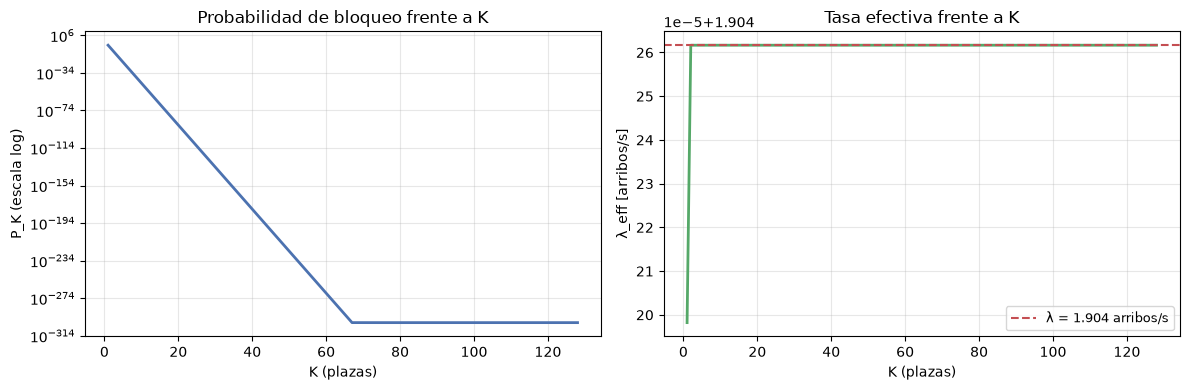

In [18]:
k_values = np.arange(1, 129)
pk_curve = np.exp(np.log1p(-rho_proxy) + k_values * np.log(rho_proxy))
eff_curve = lambda_hat * (1 - pk_curve)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].semilogy(k_values, np.maximum(pk_curve, 1e-300), color="#4C72B0", lw=2)
axes[0].set_title("Probabilidad de bloqueo frente a K")
axes[0].set_xlabel("K (plazas)")
axes[0].set_ylabel("P_K (escala log)")

axes[1].plot(k_values, eff_curve, color="#55A868", lw=2)
axes[1].axhline(lambda_hat, color="#C44E52", ls="--",
                label=f"λ = {lambda_hat:.3f} arribos/s")
axes[1].set_title("Tasa efectiva frente a K")
axes[1].set_xlabel("K (plazas)")
axes[1].set_ylabel("λ_eff [arribos/s]")
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

## 11. Dictamen de usabilidad

Cada control se clasifica como `PASA`, `ADVERTENCIA` o `FALLA`. El dictamen final es desfavorable si existe al menos una falla y condicionado si solo existen advertencias.

In [19]:
exp_row = fits.loc[fits["familia"] == "Exponencial"].iloc[0]
dominance = bssid_counts.iloc[0] / bssid_counts.sum()
controls = [
    ("Integridad del contenedor", "PASA" if len(frames) > 0 and meta["snaplen"] > 0 else "FALLA",
     f"{len(frames)} registros, enlace={meta['linktype']}, snaplen={meta['snaplen']} B"),
    ("Resolución del payload", "PASA" if truncation_ratio < 0.05 else "FALLA",
     f"fracción recortada = {truncation_ratio:.1%}"),
    ("Identificación del BSSID", "PASA" if dominance >= 0.95 else "ADVERTENCIA",
     f"servicio dominante = {dominance:.1%} de las tramas útiles"),
    ("Suficiencia muestral", "PASA" if n >= n_required else "ADVERTENCIA",
     f"n = {n}, requerido = {n_required} para ε = {REL_PRECISION:.0%}"),
    ("Independencia de interarribos", "PASA" if (p_lb > ALPHA and p_runs > ALPHA and abs(rho[0]) <= acf_bound) else "FALLA",
     f"p_LB = {p_lb:.2g}, p_rachas = {p_runs:.2g}, ρ(1) = {rho[0]:.3f}"),
    ("Proceso de Poisson (arribos M)", "PASA" if (exp_row["p_KS_boot"] > ALPHA and exp_row["p_chi2"] > ALPHA) else "FALLA",
     f"exponencial: D_n = {exp_row['D_n']:.3f}, p_KS = {exp_row['p_KS_boot']:.3g}, p_χ² = {exp_row['p_chi2']:.3g}"),
    ("Estacionariedad", "PASA" if (0.8 <= dispersion <= 1.2 and trend.pvalue > ALPHA) else "FALLA",
     f"I = {dispersion:.2f}, p_pendiente = {trend.pvalue:.3g}"),
    ("Tiempo de servicio del procesador", "FALLA",
     "la captura solo expone el tiempo de transmisión; no mide la CPU"),
    ("Pérdidas y retransmisiones", "PASA" if (frames["ftype"] == 1).any() else "FALLA",
     f"tramas de control capturadas = {int((frames['ftype'] == 1).sum())}"),
]

verdict = pd.DataFrame(controls, columns=["control", "resultado", "evidencia"])
display(verdict)

n_fail = int((verdict["resultado"] == "FALLA").sum())
n_warn = int((verdict["resultado"] == "ADVERTENCIA").sum())
if n_fail:
    conclusion = "NO APTA para calibrar un modelo M/M/1 o M/M/1/K con esta muestra."
elif n_warn:
    conclusion = "APTA con restricciones: documentar las advertencias antes de ajustar el modelo."
else:
    conclusion = "APTA: la muestra satisface los controles definidos."
print(conclusion)
print(f"Resumen: {n_fail} fallas, {n_warn} advertencias, {len(verdict) - n_fail - n_warn} controles superados.")

,control,resultado,evidencia
0,Integridad del contenedor,PASA,"3425 registros, enlace=127, snaplen=128 B"
1,Resolución del payload,FALLA,fracción recortada = 38.0%
2,Identificación del BSSID,PASA,servicio dominante = 100.0% de las tramas útiles
3,Suficiencia muestral,ADVERTENCIA,"n = 3424, requerido = 4596 para ε = 5%"
4,Independencia de interarribos,FALLA,"p_LB = 1e-264, p_rachas = 2.6e-152, ρ(1) = 0.278"
5,Proceso de Poisson (arribos M),FALLA,"exponencial: D_n = 0.288, p_KS = 0.0025, p_χ² = 0"
6,Estacionariedad,FALLA,"I = 69.58, p_pendiente = 0.385"
7,Tiempo de servicio del procesador,FALLA,la captura solo expone el tiempo de transmisió...
8,Pérdidas y retransmisiones,FALLA,tramas de control capturadas = 0


NO APTA para calibrar un modelo M/M/1 o M/M/1/K con esta muestra.
Resumen: 6 fallas, 1 advertencias, 2 controles superados.


### Panel de controles

Dos controles superan, uno advierte y seis fallan. El patrón de relleno distingue categorías sin depender solo del color.

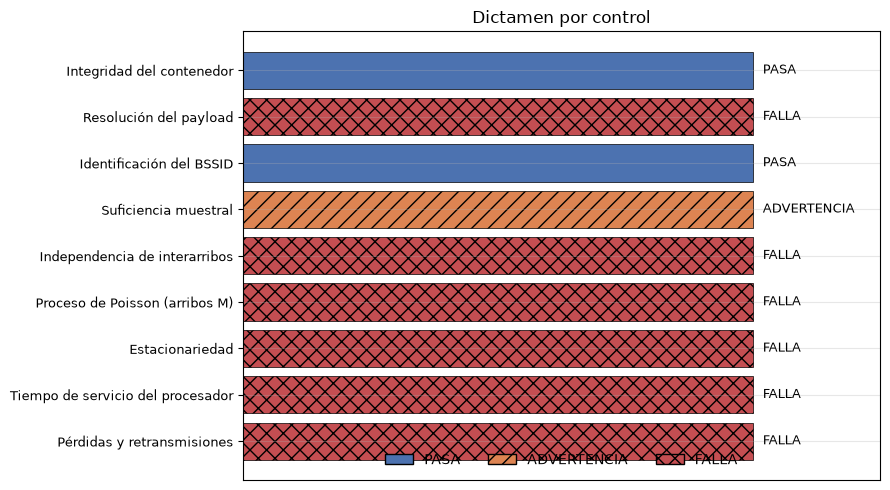

In [20]:
styles = {
    "PASA": ("#4C72B0", ""),
    "ADVERTENCIA": ("#DD8452", "//"),
    "FALLA": ("#C44E52", "xx"),
}
ordered = verdict.iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 5))
y_pos = np.arange(len(ordered))
for y, control, resultado in zip(y_pos, ordered["control"], ordered["resultado"]):
    color, hatch = styles[resultado]
    ax.barh(y, 1, color=color, edgecolor="black", linewidth=0.5, hatch=hatch)
    ax.text(1.02, y, resultado, va="center", fontsize=9)
ax.set_xlim(0, 1.25)
ax.set_xticks([])
ax.set_yticks(y_pos)
ax.set_yticklabels(ordered["control"], fontsize=9)
ax.set_title("Dictamen por control")
handles = [plt.Rectangle((0, 0), 1, 1, facecolor=c, edgecolor="black", hatch=h)
           for c, h in styles.values()]
ax.legend(handles, styles.keys(), loc="lower center", ncol=3, frameon=False)
plt.tight_layout()
plt.show()

## 12. Salida opcional y limitaciones

La tabla depurada puede exportarse para un ajuste posterior en otra herramienta. La exportación está desactivada por defecto para mantener el cuaderno libre de efectos secundarios.

In [21]:
if EXPORT_CLEAN:
    out = Path("data/arribos_depurados.csv")
    pd.DataFrame({"timestamp_s": ts, "interarrival_s": np.r_[np.nan, deltas],
                  "mpdu_len_B": mpdu, "service_proxy_s": service}).to_csv(out, index=False)
    print(f"Exportado: {out}")

Las limitaciones que condicionan cualquier conclusión son: la resolución de captura puede recortar payloads; la ausencia de tramas de control impide observar reconocimientos y reintentos; la tasa física elegida es una hipótesis y no una medición; y la congestión en el procesador no es invertible desde el tráfico de radio sin telemetría del dispositivo. En consecuencia, este cuaderno decide sobre la **calidad de la muestra**, no sobre el comportamiento real del sistema.

## 13. Conclusiones y posibles mejoras

### Conclusiones

- La captura es **NO APTA** para calibrar $M/M/1$ o $M/M/1/K$: seis de nueve controles fallan y solo uno advierte.
- El problema principal no es el tamaño de la muestra sino su estructura. Los interarribos están autocorrelacionados ($\rho(1) = 0.278$, $p_{LB} \approx 10^{-264}$) y agrupados ($I \approx 69.6$). Sumar más tramas del mismo régimen no restaura la independencia.
- El recorte del 38 % invalida cualquier análisis del payload; las marcas de tiempo y `orig_len` conservan su validez.
- El servicio observado es transmisión en el aire, no tiempo de CPU: $\rho_{\mathrm{proxy}} \approx 3.3\times10^{-5}$ es una cota inferior de la utilización, no una medida real. Sin tramas de control tampoco hay pérdidas observables.

### Posibles mejoras

1. Capturar con `snaplen` ≥ 256 B (o completo) para llevar $\tau$ por debajo del 5 %.
2. Extender la duración y repetir en varias sesiones: $n \ge 4596$ cubre la precisión del 5 %, pero hace falta además un muestreo que separe las ráfagas.
3. Habilitar tramas de control (ACK/RTS/CTS) y usar indicadores de `radiotap`/`retry` para observar retransmisiones y pérdidas.
4. Leer la tasa física real de `radiotap` (MCS/HT/VHT) en lugar de fijar 54 Mbps y recalcular $S_{\mathrm{proxy}}$ trama por trama.
5. Obtener telemetría del punto de acceso (CPU, ocupación de cola) para estimar $\mu$ de verdad; el proxy solo da una cota.
6. Evaluar modelos alternativos que admitan agrupamiento: renovación con Weibull (mejor AIC), MMPP o simulación guiada por la traza.
7. Repetir el análisis por bloques temporales hasta que $I$ se acerque a 1 antes de ajustar cualquier modelo de colas.
8. Activar `EXPORT_CLEAN` y versionar `data/arribos_depurados.csv` para ajustes posteriores, manteniendo `SEED` fijo.